In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi

In [3]:
prefix = '/mnt/staging/' 
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"
figure_config_root = str(PREPARES / "config") + "/"


mouse='cm125'

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_32885/3017678801.py:7: RuntimeWarning: invalid value encountered in cast
  props = regionprops(IDX_sorted.astype(int))


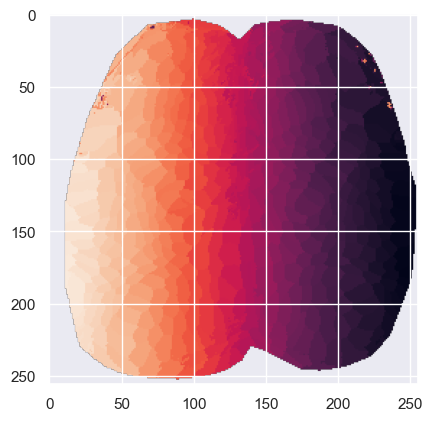

In [4]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
plt.imshow(IDX_sorted)

In [5]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


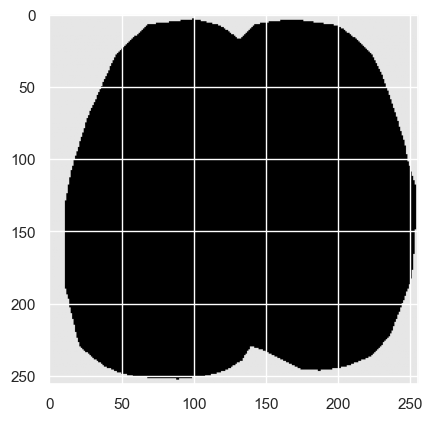

In [6]:
masked_brain_here = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain_here,nan=67000)
plt.imshow(masked_brain,cmap='gray',vmin=40000,vmax=70000)

In [7]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#cd80a1'
palatte_dict['tail'] = 'palegreen'
palatte_dict['LT'] = '#b3b3b3'
palatte_dict['RT']  = '#e4c494' ##b69d76 back up
palatte_dict['RT']  = '#b69d76' # back up

In [8]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model
def contour_to_roi(image,contour):
    import scipy.ndimage as ndimage  
    r = mask
    # Create an empty image to store the masked array
    r_mask = np.zeros_like(r, dtype='bool')
    # r_mask[:]=np.nan

    # Create a contour image by using the contour coordinates rounded to their nearest integer value
    r_mask[np.round(contour[:, 0]).astype('int'), np.round(contour[:, 1]).astype('int')] = 1

    # Fill in the hole created by the contour boundary
    r_mask = ndimage.binary_fill_holes(r_mask)

    # Invert the mask since you want pixels outside of the region
    # r_mask = ~r_mask
    
    r_mask = r_mask.astype('float')
    r_mask[r_mask == 0] = np.nan

    return r_mask



In [9]:
fetch_path_contours = str(PREPARES / "heterogeneity-contours") + "/"

clean_contours_M2=load_pickle(fetch_path_contours+'clean_contours_'+'cm125')
clean_contours_S1 = load_pickle(fetch_path_contours+'clean_contours_S1_'+'cm125')
homunculus_rois_M2 = load_pickle(fetch_path_contours+'dict_M2_full_'+mouse)
homunculus_rois_S1 = load_pickle(fetch_path_contours+'dict_S1_full_'+mouse)
dict_save = load_pickle(fetch_path_contours+'dict_save_'+mouse)
sensory_ind = dict_save['sensory_ind']
M2_ind = dict_save['M2_ind']


In [10]:
# (137,130) #bregma location
pixels_per_mm = 30
x_axis = np.divide(np.linspace(-135,256-135-1,256),pixels_per_mm)
y_axis = np.divide(np.linspace(256-136-1,-136,256),pixels_per_mm)
extent = [x_axis[0],x_axis[-1],y_axis[-1],y_axis[0]]


In [11]:
palatte_dict['RW']='#6932a5' #slightly brighter
bdp_w_order = [ 'RHP','RFP', 'LM','RM', 'RW','LHP','LFP','LW','LN','RN','LV','RV']

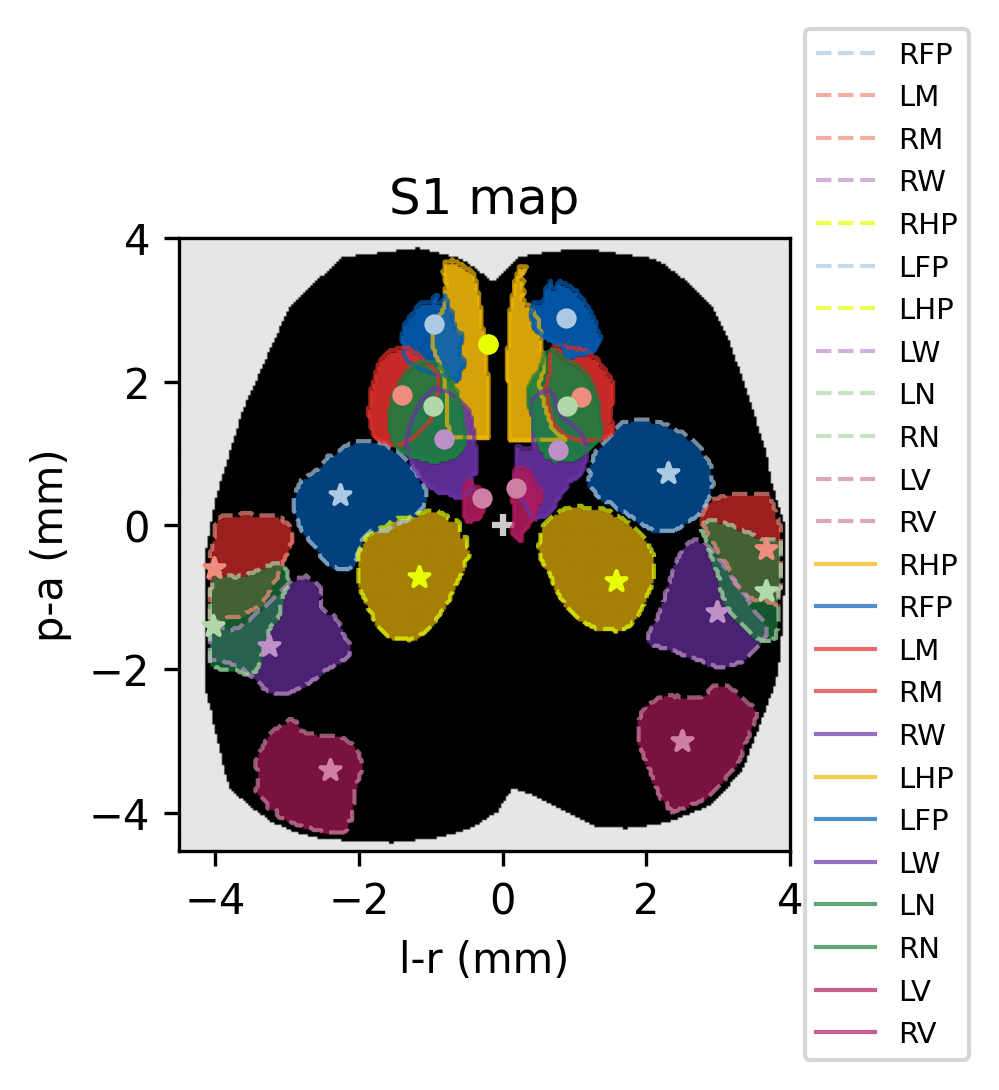

In [12]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)



y_offset = 20;x_offset=20;
x_width=9;
x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+9,x_start:x_stop])

ax0.imshow(masked_brain,cmap='gray',vmin=40000,vmax=70000,extent=extent)

for ikey,bodypart_name in enumerate([ 'RFP', 'LM', 'RM','RW','RHP','LFP','LHP','LW','LN','RN','LV','RV']):
    for contour in clean_contours_S1[bodypart_name]:
        bodypart_name_here=bodypart_name.replace('L','R')
        # ===================
        r_mask = contour_to_roi(np.ones((256,256)),contour)
        c_black= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_here],alpha = 0.7)
        c_black1= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_here],alpha = 0.6)
        c_white= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_here],alpha = 0.5)
        cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)
        ax0.imshow(r_mask,vmin=0.1,vmax=1,cmap=cmap_rb,extent=extent)

        ax0.plot((contour[:,1]-135)/pixels_per_mm,(256-contour[:,0]-136)/pixels_per_mm,linewidth=1,linestyle='dashed',alpha=0.7,label=bodypart_name,color=palatte_dict[bodypart_name.replace('R','L')])


for ikey,bodypart_name in enumerate([ 'RHP','RFP', 'LM','RM', 'RW','LHP','LFP','LW','LN','RN','LV','RV']):
    for contour in clean_contours_M2[bodypart_name]:
        bodypart_name_here=bodypart_name.replace('L','R')
        # ===================
        r_mask = contour_to_roi(np.ones((256,256)),contour)
        c_black= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_here],alpha = 0.9)
        c_black1= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_here],alpha = 0.8)
        c_white= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_here],alpha = 0.6)
        cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)

        ax0.imshow(r_mask,vmin=0.1,vmax=1,cmap=cmap_rb,extent=extent)
        ax0.plot((contour[:,1]-135)/pixels_per_mm,(256-contour[:,0]-136)/pixels_per_mm,linewidth=1,alpha=0.7,label=bodypart_name,color=palatte_dict[bodypart_name_here])

# --- NEW: Plot S1 and M2 Scatter Points ---
for i in range(12):
    bdp = bdp_w_order[i]
    S1_region_number = sensory_ind[bdp]
    M2_region_number = M2_ind[bdp]
    
    # 1. Fetch raw pixel coordinates (Assuming node_coords is formatted as [Y, X])
    s1_y_pix, s1_x_pix = node_coords[S1_region_number, 0], node_coords[S1_region_number, 1]
    m2_y_pix, m2_x_pix = node_coords[M2_region_number, 0], node_coords[M2_region_number, 1]
    
    # 2. Convert to mm using your exact contour transformation math to match the extent
    s1_x_mm = (s1_x_pix - 135) / pixels_per_mm
    s1_y_mm = (256 - s1_y_pix - 136) / pixels_per_mm
    
    m2_x_mm = (m2_x_pix - 135) / pixels_per_mm
    m2_y_mm = (256 - m2_y_pix - 136) / pixels_per_mm
    
    # 3. Scatter plot on top (zorder=10 ensures they render above contours/images)
    # Using 'o' (circle) for S1 and '^' (triangle) for M2 to differentiate them
    ax0.scatter(s1_x_mm, s1_y_mm, color=palatte_dict[bdp.replace('R','L')], marker='*', s=25, zorder=10)
    ax0.scatter(m2_x_mm, m2_y_mm, color=palatte_dict[bdp.replace('R','L')], s=15, zorder=10)
        
ax0.scatter(0,0,s=30,marker='+',color='white',alpha=0.8) #bregma location
ax0.legend(loc='center left',fontsize=7, bbox_to_anchor=(1, 0.5))
ax0.set_title('S1 map')
ax0.set_xlabel('l-r (mm)')
ax0.set_ylabel('p-a (mm)')
ax0.set_xticks([-4,-2,0,2,4])
ax0.set_yticks([-4,-2,0,2,4])

plt.savefig('fig3-M2-S1-topography-heterogeneity.svg',format='svg',dpi=300)

